https://stackoverflow.com/a/44214229

# **Final Year Project - Year 4 Software Development**
## Iteration 2 - Assessing a User's Skill

*By Mark Lambert - C00192497*

*14/11/2026*

---

I spent some time testing the current onset and chord detection, and faced some difficulties when trying to cleanly get a recording that detects every major chord

This notebook investigates this issue by once again digging deeper and plotting the onsets to understand what's going wrong

In [9]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

clip, sr = librosa.load("../data/clips/sample/all_chords.wav", sr=None)

raw_onsets = librosa.onset.onset_detect(y=clip, sr=sr)
raw_onset_times = librosa.frames_to_time(raw_onsets, sr=sr)
rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
total_frames = len(rms)

rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])

valid_threshold = 0.2 * rms.max()
frame_offset = 2
buffer = 0.5

# lists of tuples w/ (start, end) frames
strum_group = []
transition_group = []

# list of valid strum onsets detected by rms
strums_end = []
strums_start = []
# find strum end onsets
for i in range(len(onset_frames)):
    frame = onset_frames[i]

    # only check for strum end onsets if there has already been a detected onset
    if i > 0:
        prev = onset_frames[i-1]
        cur = onset_frames[i]

        frame_since_last = cur - prev
        if librosa.frames_to_time(frame_since_last, sr=sr) > buffer:
            strums_end.append(cur)
            continue
    
    # find starts w/ rms
    if frame < len(rms):
        curr = rms[frame]
        prev = rms[frame-frame_offset]
    
    # check if above valid threshold (filter noise) and
    # curr is louder than preevious, showing rise in energy
    if curr > valid_threshold and curr > 1.4 * prev:
        strums_start.append(frame)

# sort the strum list so that they are in chronological order
strums_end = sorted(set(strums_end))
strums_end = librosa.frames_to_time(strums_end, sr=sr)
strums_start = sorted(set(strums_start))
strums_start = librosa.frames_to_time(strums_start, sr=sr)

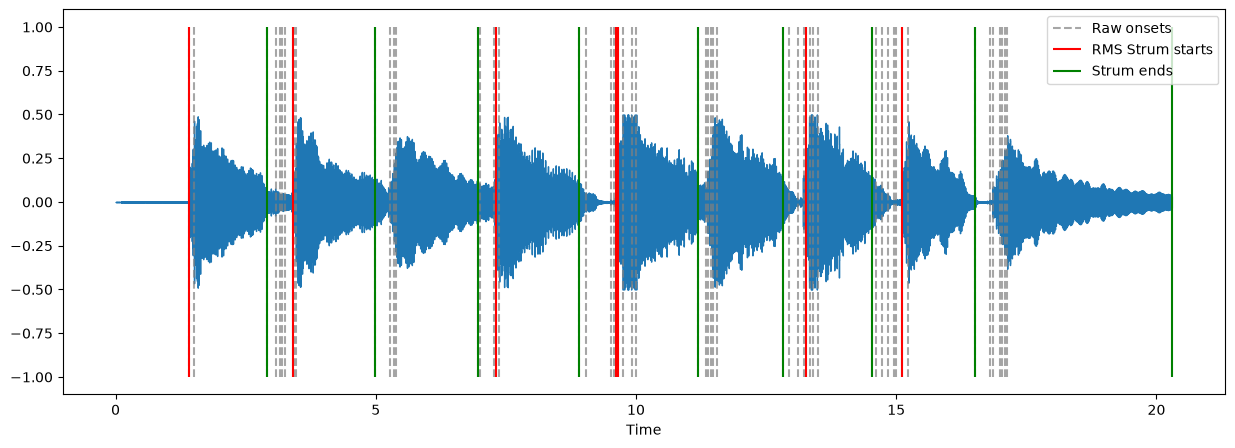

In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(strums_start, -1, 1, color="red", linestyle="-", label="RMS Strum starts")
ax.vlines(strums_end, -1, 1, color="green", linestyle="-", label="Strum ends")
ax.set_xlabel("Time")
ax.legend()
plt.show()

So, the red lines show that the rms based detection is not currently reliable, with the logic failing to detect three of the 9 played chords